In [17]:
import pandas as pd
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [18]:
iris = load_iris()
X = iris.data
y = iris.target

In [19]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

In [21]:
df_labels = pd.read_csv("iris_labels.txt", header=None)
ampl_labels = df_labels.iloc[:, 0].values

df_medoids = pd.read_csv("iris_medoids.txt", header=None)
ampl_medoids = df_medoids.iloc[:, 0].values - 1

X_medoids_pca = X_pca[ampl_medoids]

# # Utilisation dans votre scatter plot PCA
# scatter = plt.scatter(
#     X_pca[:, 0],
#     X_pca[:, 1],
#     c=ampl_labels,  # Correspond exactement aux 150 points de iris_m150.dat
#     cmap="viridis_r",
#     edgecolor="k",
#     s=60,
#     alpha=0.85,
# )
# plt.colorbar(scatter, label="Clusters k-medoids")
# plt.show()

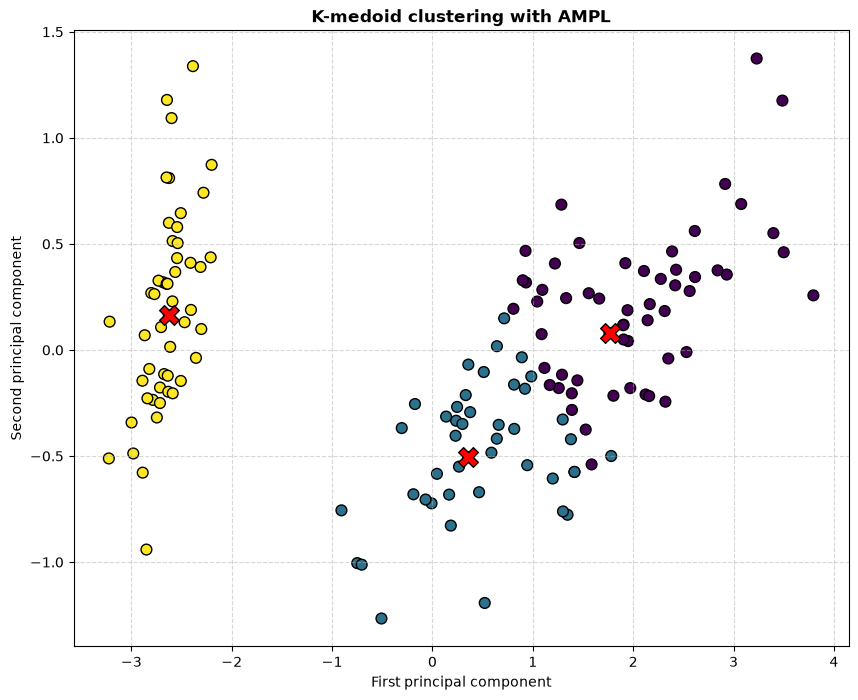

In [23]:
plt.figure(figsize=(10, 8))

# scatter plot des points colorés selon les labels de clusters d'AMPL
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=ampl_labels,  # Le tableau/liste des labels renvoyés par AMPL
    cmap='viridis_r',  # Palette viridis inversée (jaune/violet)
    edgecolor='k',
    s=60,
    alpha=1,
)


plt.scatter(
    X_medoids_pca[:, 0],
    X_medoids_pca[:, 1],
    c='red',
    marker='X',
    s=200,
    edgecolor='black',
    label='Medoids',
    zorder=3,
)

# Ajout des éléments de mise en page
plt.title(
    'K-medoid clustering with AMPL',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('First principal component')
plt.ylabel('Second principal component')
plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig("iris_kmedoids_ampl.png")
plt.show()